In [16]:
import random
import time
import copy

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство для вычислений:', device)
#if device.type == 'cuda':
if device == 'cuda':
    print('Видеокарта:', torch.cuda.get_device_name(0))

Устройство для вычислений: cuda
Видеокарта: Tesla T4


In [17]:
DATA_DIR = './data'
raw_train = datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
raw_test = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

# Случайно делим 50 000 обучающих картинок на train (45 000) и validation (5 000)
VAL_SIZE = 5000
generator = torch.Generator().manual_seed(42)
perm = torch.randperm(len(raw_train), generator=generator).tolist()
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

# Считаем среднее и стандартное отклонение каждого канала ТОЛЬКО по обучающей части
train_pixels = raw_train.data[train_idx] / 255.0          # форма (45000, 32, 32, 3) (N, H, W, C)
mean = train_pixels.mean(axis=(0, 1, 2))                 # усреднение внутри каждого канала отдельно
std = train_pixels.std(axis=(0, 1, 2))
print('Среднее по каналам (R, G, B) обучающей выборки:', mean.round(4))
print('Стандартное отклонение (R, G, B) обучающей выборки:', std.round(4))

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

train_ds = Subset(torchvision.datasets.CIFAR10(root='./data', train=True, transform=train_transform), train_idx)
val_ds = Subset(torchvision.datasets.CIFAR10(root='./data', train=True, transform=eval_transform), val_idx)
test_ds = torchvision.datasets.CIFAR10(root='./data', train=False, transform=eval_transform)

Среднее по каналам (R, G, B) обучающей выборки: [0.4913 0.4822 0.4466]
Стандартное отклонение (R, G, B) обучающей выборки: [0.247  0.2436 0.2617]


In [18]:
BATCH_SIZE = 128

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

In [19]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [20]:
# --- Размерности данных ---
print('Количество примеров:')
print(f'  train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}')
print('Исходный массив изображений train:', raw_train.data.shape, '→ (N, H, W, C)')
print('Массив меток train:', np.array(raw_train.targets).shape)

img, label = train_ds[0]
print('Форма одного изображения после преобразований:', tuple(img.shape), '→ (C, H, W)')
print('Метка:', label, '→', classes[label], '(одно целое число)')

images, labels = next(iter(train_loader))
print('Форма батча изображений:', tuple(images.shape))
print('Форма батча меток:', tuple(labels.shape))

Количество примеров:
  train: 45000, val: 5000, test: 10000
Исходный массив изображений train: (50000, 32, 32, 3) → (N, H, W, C)
Массив меток train: (50000,)
Форма одного изображения после преобразований: (3, 32, 32) → (C, H, W)
Метка: 4 → deer (одно целое число)
Форма батча изображений: (128, 3, 32, 32)
Форма батча меток: (128,)


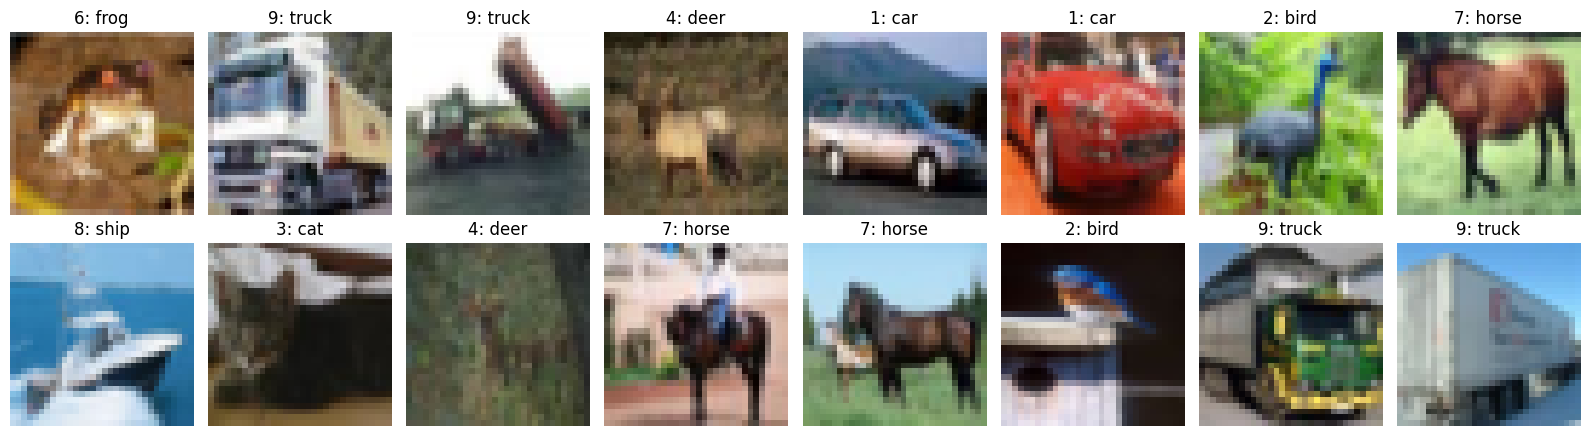

In [21]:
# --- Примеры изображений с метками ---
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(raw_train.data[i])
    ax.set_title(f'{raw_train.targets[i]}: {classes[raw_train.targets[i]]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [22]:
def conv_bn_relu(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn_relu(3, 64),
            conv_bn_relu(64, 64),
            nn.MaxPool2d(kernel_size=2),

            conv_bn_relu(64, 128),
            conv_bn_relu(128, 128),
            nn.MaxPool2d(kernel_size=2),

            conv_bn_relu(128, 256),
            conv_bn_relu(256, 256),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [23]:


model = CifarCNN().to(device)
print(model)
print(f"Параметров: {sum(p.numel() for p in model.parameters()):,}")

CifarCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (4): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(

In [24]:
def evaluate(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return loss_sum / total, correct / total

Эпоха 1: train_loss=2.017, train_acc=21.34%, val_loss=1.876, val_acc=25.68%
Эпоха 2: train_loss=1.758, train_acc=30.77%, val_loss=1.499, val_acc=43.28%
Эпоха 3: train_loss=1.472, train_acc=45.26%, val_loss=1.293, val_acc=53.14%
Эпоха 4: train_loss=1.171, train_acc=58.80%, val_loss=0.947, val_acc=65.94%
Эпоха 5: train_loss=0.985, train_acc=66.24%, val_loss=0.777, val_acc=73.20%
Эпоха 6: train_loss=0.862, train_acc=71.05%, val_loss=0.803, val_acc=73.76%
Эпоха 7: train_loss=0.771, train_acc=74.46%, val_loss=0.713, val_acc=75.68%
Эпоха 8: train_loss=0.692, train_acc=77.58%, val_loss=0.683, val_acc=76.84%
Эпоха 9: train_loss=0.627, train_acc=79.66%, val_loss=0.559, val_acc=81.04%
Эпоха 10: train_loss=0.581, train_acc=81.12%, val_loss=0.602, val_acc=80.52%
Эпоха 11: train_loss=0.545, train_acc=82.54%, val_loss=0.596, val_acc=81.18%
Эпоха 12: train_loss=0.506, train_acc=83.79%, val_loss=0.507, val_acc=82.78%
Эпоха 13: train_loss=0.484, train_acc=84.68%, val_loss=0.609, val_acc=80.40%
Эпоха 14

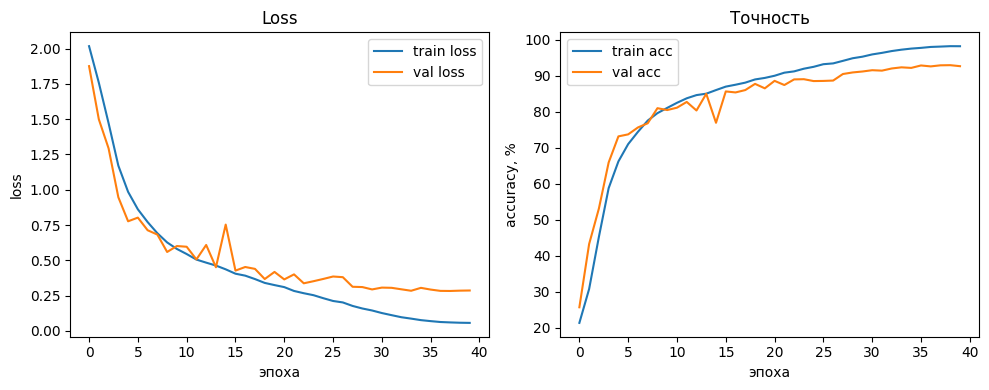

In [25]:
# --- Обучение на 40 эпох ---
epochs = 40

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}


best_val_acc, best_epoch, best_state = 0.0, 0, None

start = time.time()

for ep in range(epochs):

    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    val_loss, val_acc = evaluate(model, val_loader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Эпоха {ep + 1}: train_loss={train_loss:.3f}, train_acc={train_acc * 100:.2f}%, "
          f"val_loss={val_loss:.3f}, val_acc={val_acc * 100:.2f}%")

    scheduler.step()

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, ep + 1
        best_state = copy.deepcopy(model.state_dict())

print(f'\nОбучение заняло {(time.time() - start) / 60:.1f} мин.')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='train loss')
plt.plot(history['val_loss'], label='val loss')
plt.xlabel('эпоха'); plt.ylabel('loss'); plt.legend(); plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot([a * 100 for a in history['train_acc']], label='train acc')
plt.plot([a * 100 for a in history['val_acc']], label='val acc')
plt.xlabel('эпоха'); plt.ylabel('accuracy, %'); plt.legend(); plt.title('Точность')

plt.tight_layout()
plt.show()

In [26]:
# --- Финальная проверка на тестовой выборке (один раз!) ---
model.load_state_dict(best_state)          # берём веса лучшей эпохи по валидации
test_loss, test_acc = evaluate(model, test_loader)

print(f'Лучшая эпоха по валидации: {best_epoch} (val accuracy = {best_val_acc * 100:.2f}%)')
print(f'Тест: loss = {test_loss:.3f}, accuracy = {test_acc * 100:.2f}%')
print(f'Ошибка классификации на тесте: {(1 - test_acc) * 100:.2f}%')

# Accuracy по каждому классу
model.eval()
correct_per_class = [0] * 10
total_per_class = [0] * 10
with torch.no_grad():
    for xb, yb in test_loader:
        preds = model(xb.to(device)).argmax(1).cpu()
        for p, y in zip(preds, yb):
            total_per_class[y] += 1
            correct_per_class[y] += int(p == y)

print('\nAccuracy по классам:')
for i, name in enumerate(classes):
    print(f'  {name:6s}: {correct_per_class[i] / total_per_class[i] * 100:.2f}%')

Лучшая эпоха по валидации: 39 (val accuracy = 93.00%)
Тест: loss = 0.306, accuracy = 91.96%
Ошибка классификации на тесте: 8.04%

Accuracy по классам:
  plane : 92.60%
  car   : 96.60%
  bird  : 88.50%
  cat   : 83.70%
  deer  : 92.60%
  dog   : 87.60%
  frog  : 94.90%
  horse : 92.40%
  ship  : 95.60%
  truck : 95.10%
